# 1 - Exploration

Données réelles (https://archive.ics.uci.edu/dataset/320/student+performance) :
* proviennent de l'étude de Cortez & Silva (2008)
* ont été collectées en 2005-2006 dans deux lycées portugais, à travers des bulletins scolaires et des questionnaires

Nous travaillerons sur le jeu de données portugais.

# Importation des librairies

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Importation du jeu de données

On utilise `encoding="utf-8-sig"` pour retirer le BOM (*Byte Order Mark*) devant le nom des colonnes.

In [20]:
%load_ext autoreload
%autoreload 2
import outils as ot
df = ot.load_data()
df.info()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  ac

# Exploration du jeu de données

Le DataFrame contient 649 lignes et 33 colonnes.

In [18]:
df.describe().round(2)

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00
mean,16.74,2.51,2.31,1.57,1.93,0.22,3.93,3.18,3.18,1.50,2.28,3.54,3.66,11.40,11.57,11.91
std,1.22,1.13,1.10,0.75,0.83,0.59,0.96,1.05,1.18,0.92,1.28,1.45,4.64,2.75,2.91,3.23
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00
25%,16.00,2.00,1.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,2.00,0.00,10.00,10.00,10.00
50%,17.00,2.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,2.00,11.00,11.00,12.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,6.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,32.00,19.00,19.00,19.00


Pour chacune des colonnes numériques, il n'y a aucune valeur manquante : `count` = 649 à chaque fois.

`G3` est notre cible à prédire.

Nous remarquons également que `G1`, `G2` et `G3` sont très proches. Si la corrélation s'avère être réellement très élevée, il peut être pertinent de retirer `G1` et `G2` des modèles afin qu'ils soient plus informatifs.

Un minimum de 0 pour `G3` semble suspect, regardons combien d'élèves cela concerne.

In [19]:
df[df.G3 == 0]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
163,GP,M,18,U,LE3,T,1,1,other,other,...,2,3,5,2,5,4,0,11,9,0
440,MS,M,16,U,GT3,T,1,1,at_home,services,...,5,4,5,4,5,3,0,7,0,0
519,MS,M,16,R,GT3,T,2,1,other,services,...,5,2,1,1,1,2,0,8,7,0
563,MS,M,17,U,GT3,T,2,2,other,other,...,1,2,1,2,3,5,0,7,0,0
567,MS,M,18,R,GT3,T,3,2,services,other,...,2,3,1,2,2,5,0,4,0,0
583,MS,F,18,R,GT3,T,2,2,other,other,...,5,5,5,1,1,3,0,8,6,0
586,MS,F,17,U,GT3,T,4,2,teacher,services,...,5,5,5,1,3,5,0,8,8,0
597,MS,F,18,R,GT3,T,2,2,at_home,other,...,4,3,3,1,1,4,0,9,0,0
603,MS,F,18,R,LE3,A,4,2,teacher,other,...,5,3,1,1,1,5,0,5,0,0
605,MS,F,19,U,GT3,T,1,1,at_home,services,...,5,5,5,2,3,2,0,5,0,0


15 élèves ont donc une note pour `G3` nulle. Et pourtant, ils n'ont aucune absence. Peut-être que lorsqu'un.e élève quitte l'établissement, ce n'est pas pris en compte dans les absences.

In [39]:
zeros = df[df.G3 == 0]
print("Proportion de MS pour G3=0 :", (zeros.school == "MS").mean().round(2), "| dans tout le jeu :", (df.school == "MS").mean().round(2))
print("absences=0 pour G3=0 :", (zeros.absences == 0).mean().round(2), "| pour le reste :", (df[df.G3 > 0].absences == 0).mean().round(2))
print("G2=0 pour G3=0 :", (zeros.G2 == 0).sum(), "/", len(zeros))

Proportion de MS pour G3=0 : 0.93 | dans tout le jeu : 0.35
absences=0 pour G3=0 : 1.0 | pour le reste : 0.36
G2=0 pour G3=0 : 7 / 15


93% des élèves qui ont eu `G3 = 0` proviennet de l'école `MS` alors qu'elle ne représente que 35% du jeu de données : il y a une **concentration anormale**.

100% des élèves qui ont eu `G3 = 0` n'ont eu aucune absence enregistrée au cours de l'année. Ce qui est assez contre-intuitif.

Regardons la distribution de `G3`.

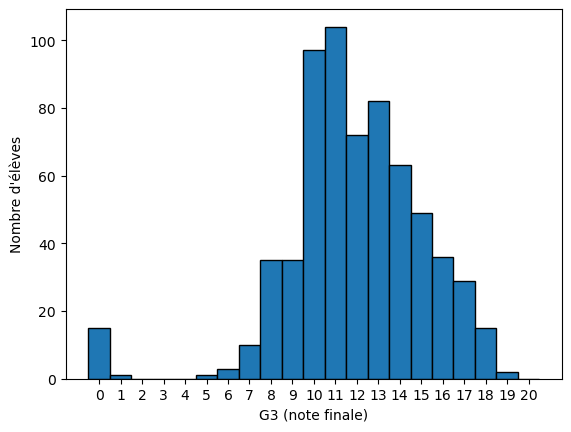

In [21]:
plt.hist(df["G3"], bins=np.arange(-0.5, 21, 1), edgecolor="black")
plt.xlabel("G3 (note finale)")
plt.ylabel("Nombre d'élèves")
plt.xticks(range(0, 21))
plt.show()

La distribution principale est proche d'une loi normale, en cloche. Le pic se situant entre 10 et 12.

Les élèves qui ont 0 et 1 semblent à part. Nous pourrions être tentés de les exclure mais cela fausserait le modèle car nous ignorerions toute une frange d'élèves en difficulté. 

Regardons la distribution de toutes les variables.

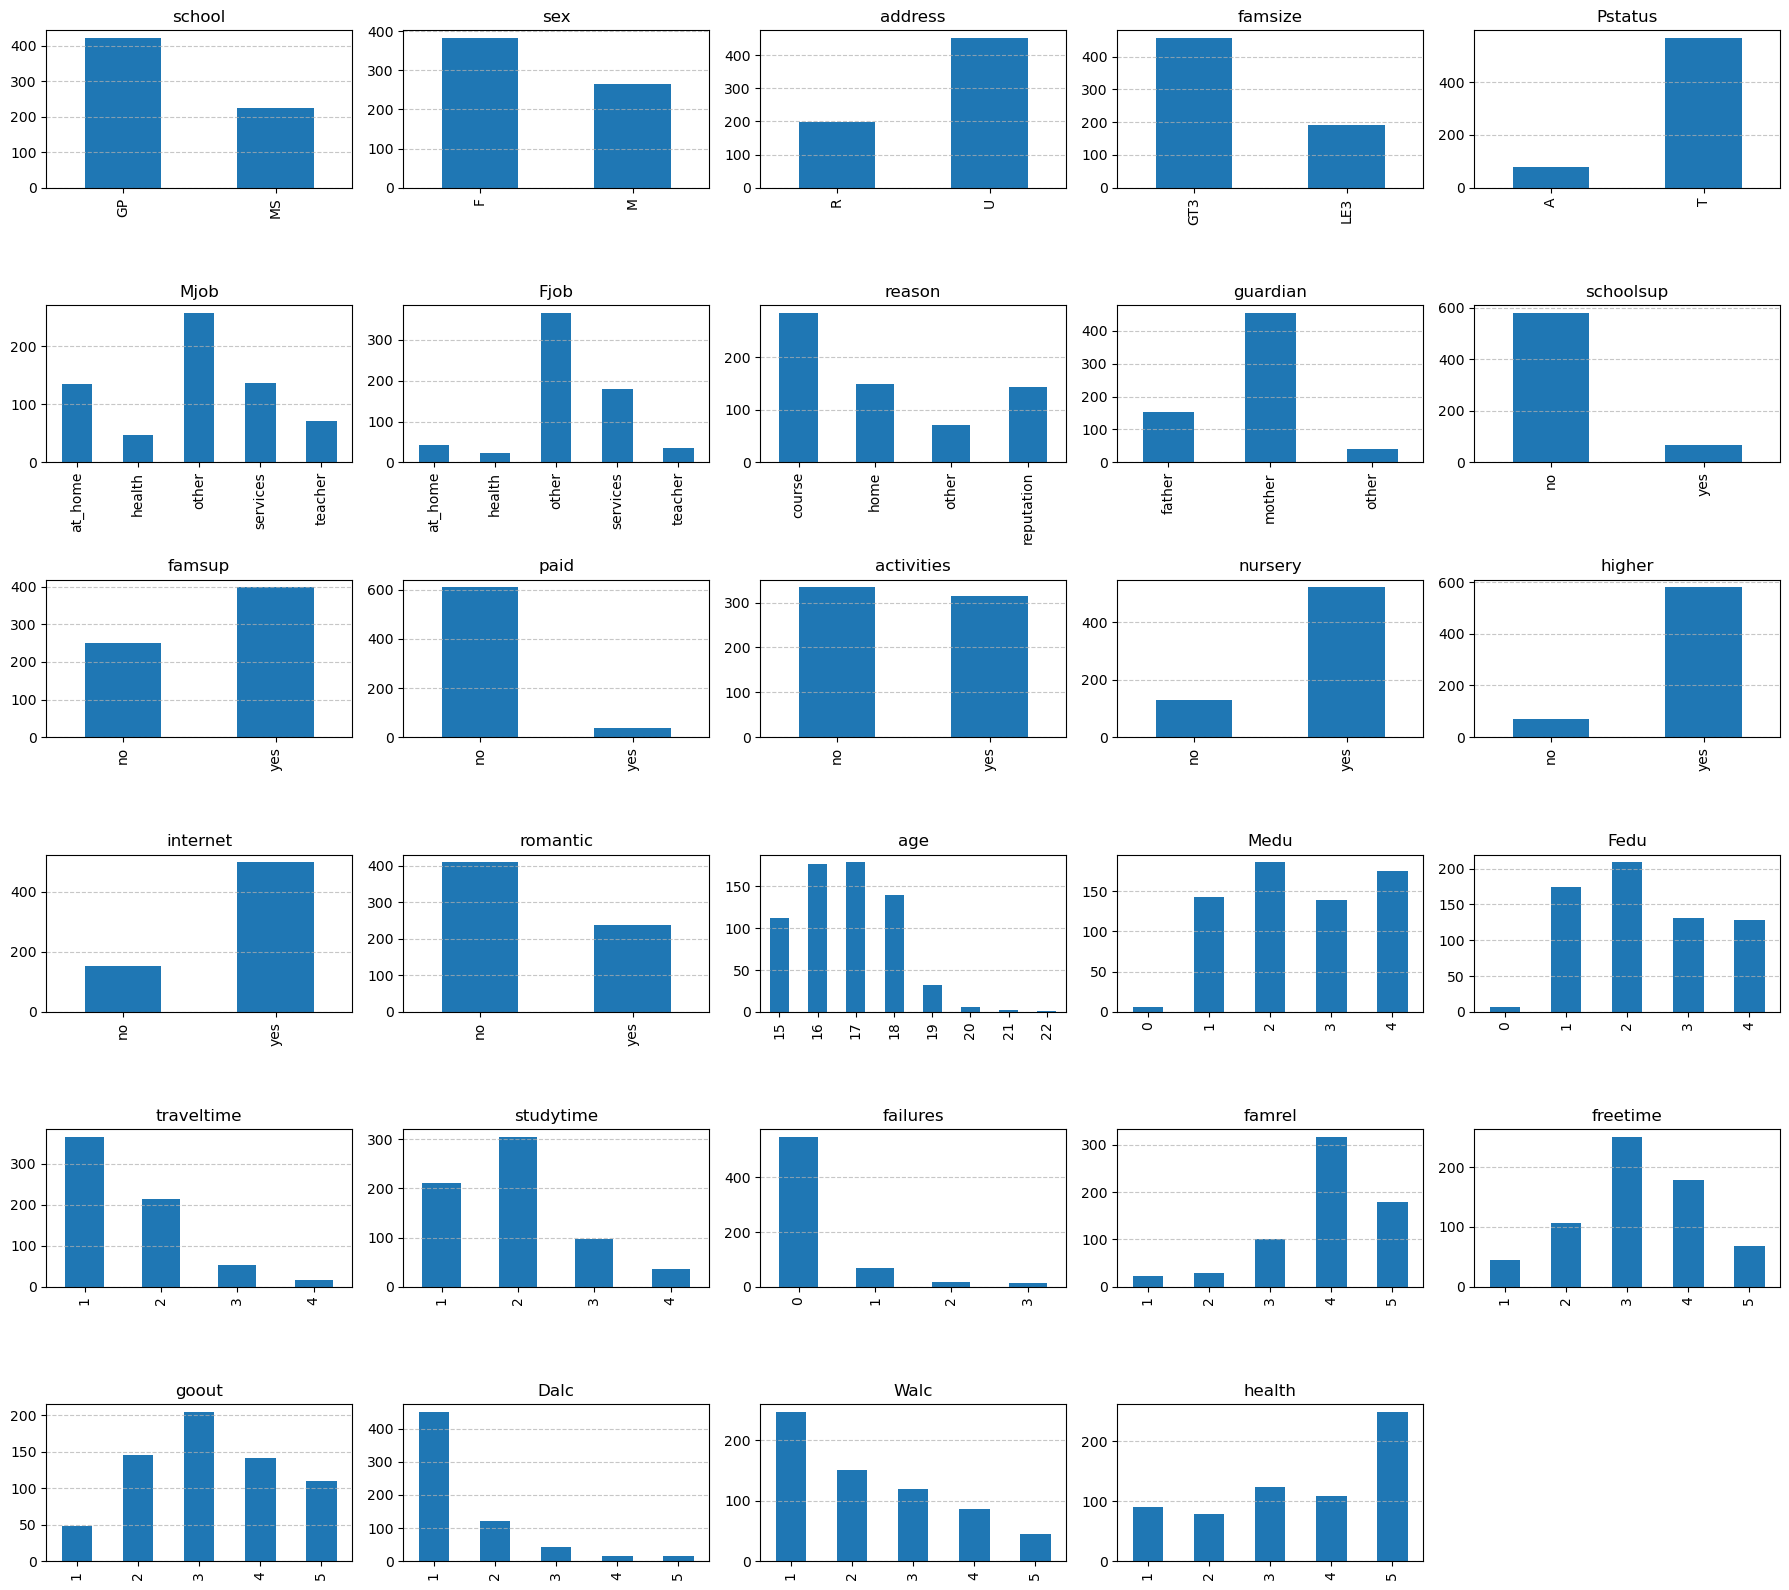

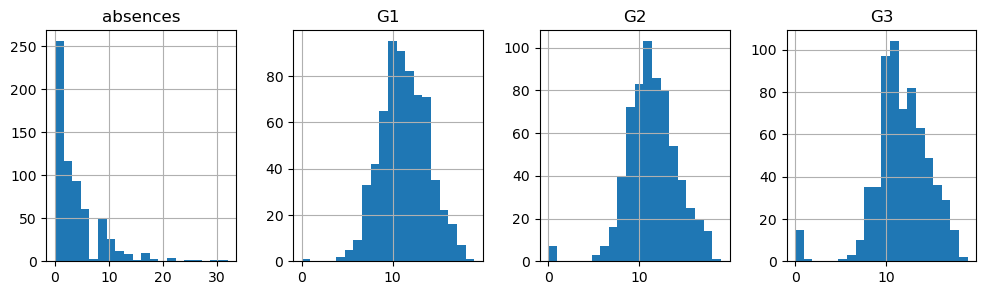

In [ ]:
cols = ot.CATEGORICAL + [c for c in ot.NUMERIC if c != "absences"]
fig, axes = plt.subplots(6, 5, figsize=(18, 16))
for ax, c in zip(axes.ravel(), cols): #.ravel() permet d'applatir la grille pour un parcours plus simple
    df[c].value_counts().sort_index().plot.bar(ax=ax, title=c)
    ax.set_xlabel("")
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")                    # n'affiche pas les cases vides 
plt.tight_layout()
plt.show()

# nous traitons ces variables à part car elles ont beaucoup de valeurs distinctes
df[["absences", "G1", "G2", "G3"]].hist(bins=20, figsize=(12, 3), layout=(1, 4))
plt.show()

Nous remarquons que certaines classes sont très déséquilibrées. Par exemple : `paid` et `higher`, contrairement à `activities`. Si les modalités sont très **rares**, les modèles auront peu d'exemples pour en apprendre l'effet : elles sont **peu informatives**, sauf si la minorité est fortement reliée à `G3`.

La distribution des `absences` est asymétrique : la plupart des élèves ont très peu d'absences, et une minorité d'élèves ont un nombre d'absences conséquent. 

Les variables `G1`, `G2` et `G3` ont des distributions similaires : en cloche avec des zéros isolés.

## Corrélations

### Variables numériques

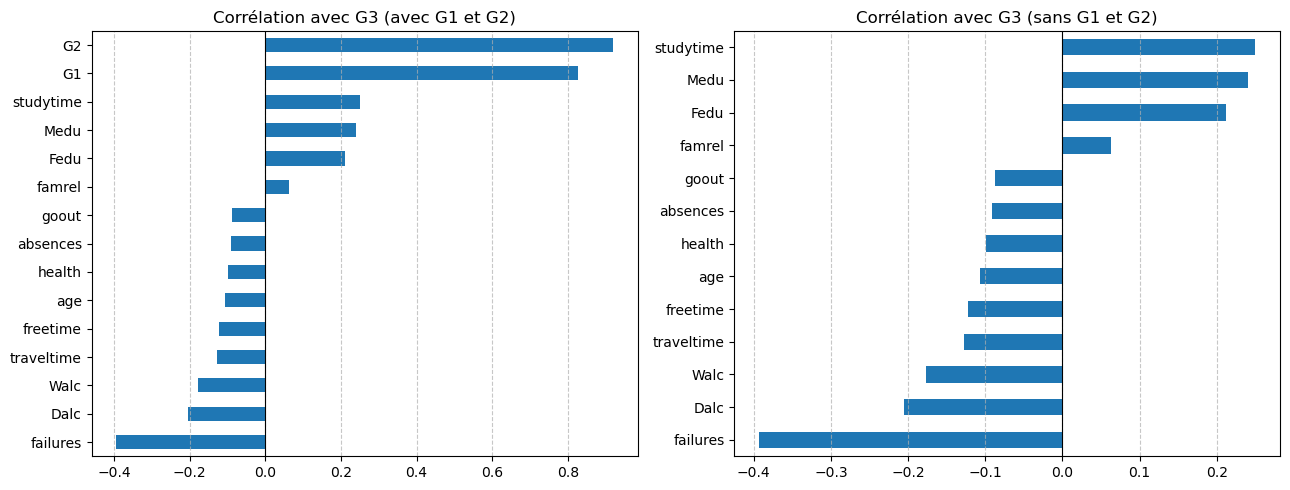

In [27]:
num_cols = ot.NUMERIC + ["G1", "G2", "G3"]
corr = df[num_cols].corr()["G3"].drop("G3").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
corr.plot.barh(ax=axes[0], title="Corrélation avec G3 (avec G1 et G2)")
corr.drop(["G1", "G2"]).plot.barh(ax=axes[1], title="Corrélation avec G3 (sans G1 et G2)")
for ax in axes:
    ax.axvline(0, color="black", lw=0.8)
    ax.grid(True, axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Sur le graphique de gauche, nous observons que `G1` et `G2` ont une très forte corrélation positive avec `G3` (cible) : 0,8 à 0,9. Si nous conservons `G1` et `G2` pour notre modèle, il est probable que les autres variables deviennent alors inutiles.

Outre les notes intermédiaires `G1` et `G2`, le temps de travail par semaine (`studytime`), le niveau d'éducation des parents (`Medu` et `Fedu`) sont les 3 variables les plus corrélées positivement à `G3`. Le nombre de matières échouées (`failures`) présente la corrélation négative la plus forte : près de -0,4.

Traçons une matrice de corrélation avec les variables numériques.

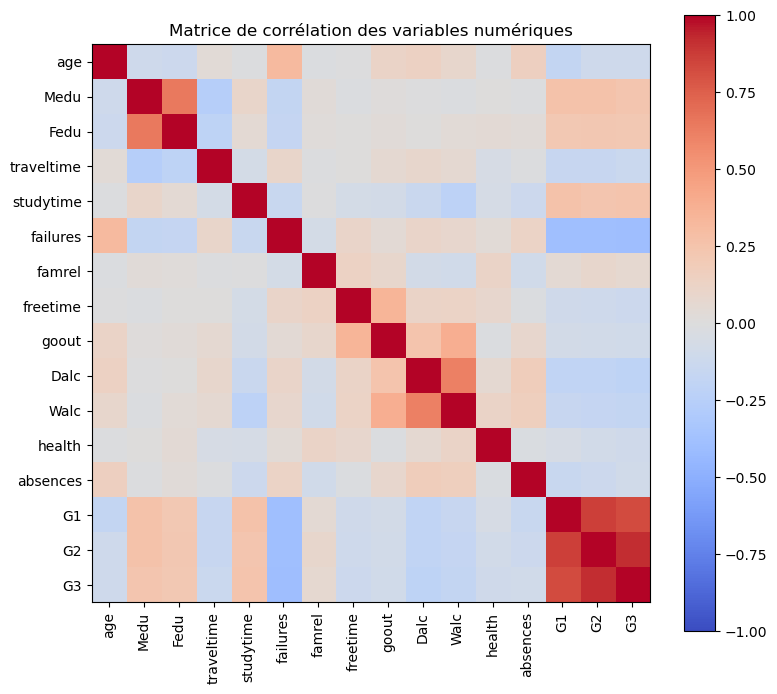

In [29]:
cm = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm)))
ax.set_xticklabels(cm.columns, rotation=90) # faire pivoter le texte
ax.set_yticks(range(len(cm)))
ax.set_yticklabels(cm.columns)
fig.colorbar(im)
ax.set_title("Matrice de corrélation des variables numériques")
plt.show()

### Variables catégorielles

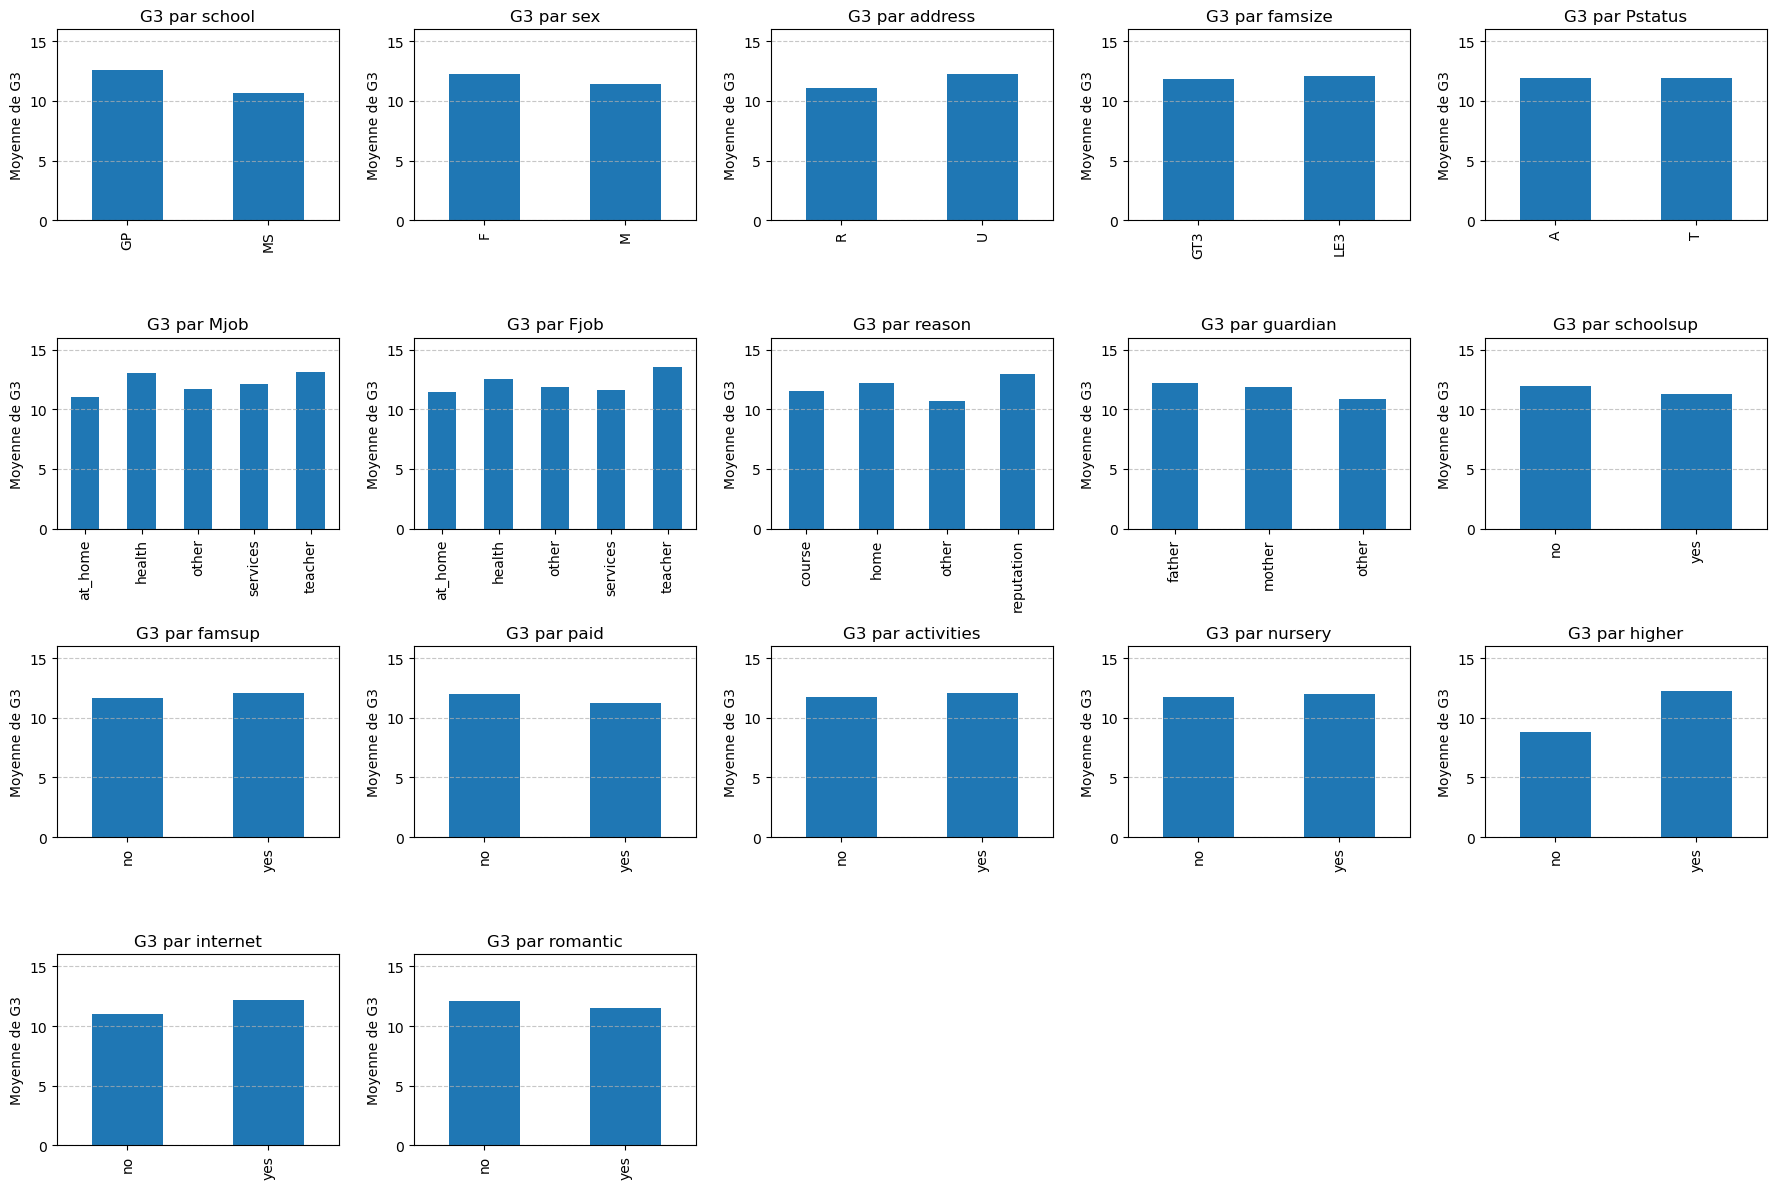

In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(18, 12))
for ax, c in zip(axes.ravel(), ot.CATEGORICAL):
    df.groupby(c)["G3"].mean().plot.bar(ax=ax, title=f"G3 for {c}", ylim=(0, 16))
    ax.set_xlabel("")
    ax.set_ylabel("Moyenne de G3")
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
for ax in axes.ravel()[len(ot.CATEGORICAL):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Nous remarquons que l'impact de certaines variables catégorielles est important sur `G3` : par exemple `school`, `higher`, `Mjob` et `Fjob`.

Beaucoup d'autres variables semblent au contraire être neutres.

Regardons cela de plus près sans prendre en compte `G3 = 0` car cela tire la moyenne vers le bas.

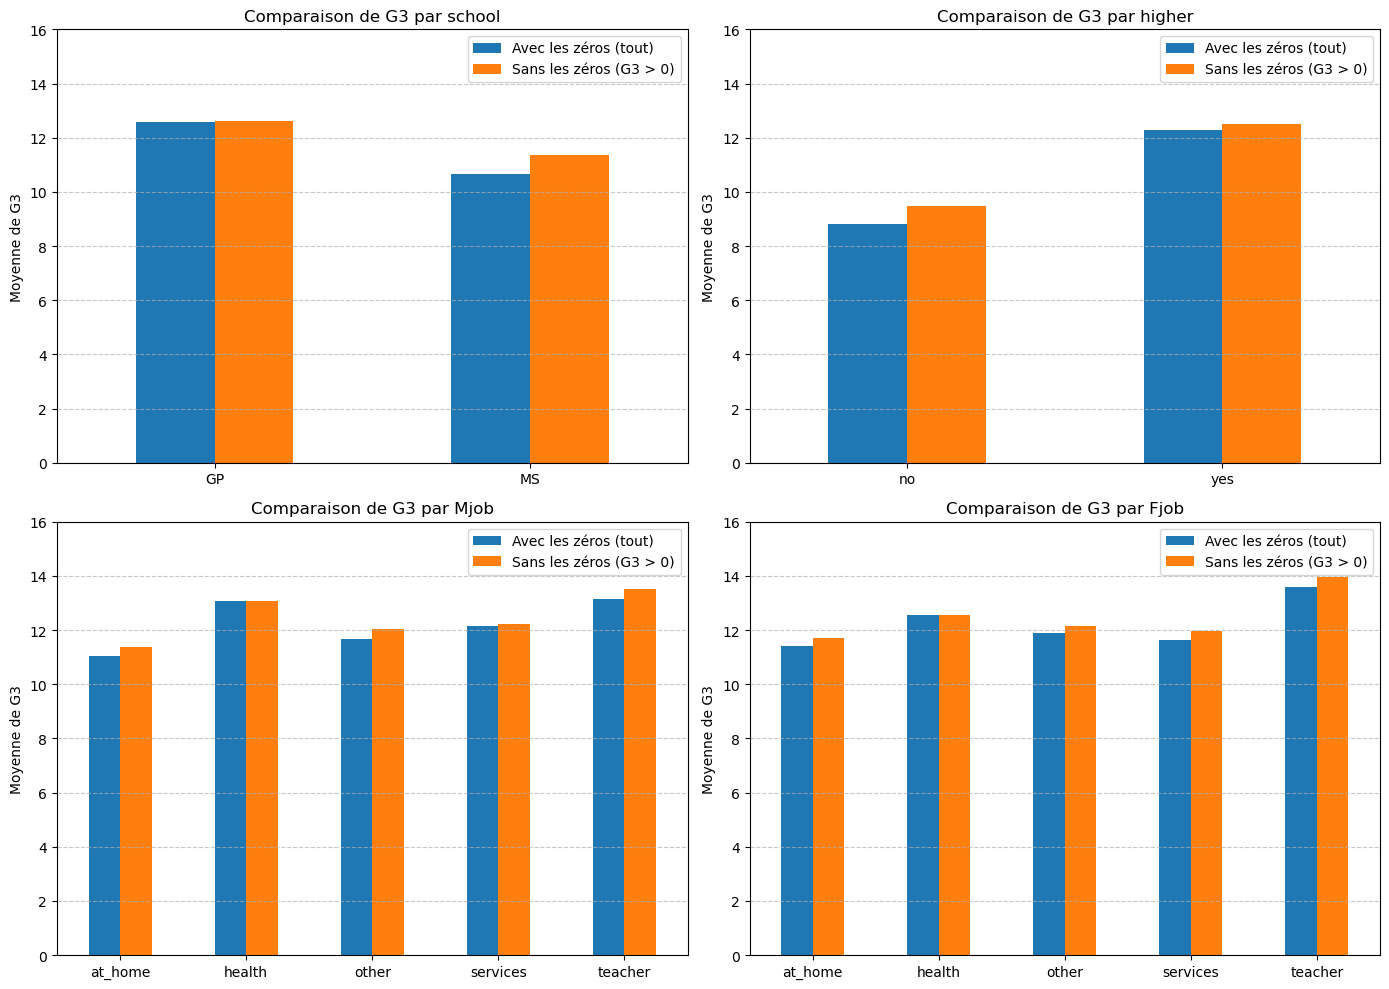

In [ ]:
# Création d'un DataFrame sans G3 = 0
d = df[df.G3 > 0]
cols_to_plot = ["school", "higher", "Mjob", "Fjob"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, c in zip(axes.ravel(), cols_to_plot):
    t = pd.concat([
        df.groupby(c)["G3"].agg(["count", "mean"]).add_suffix("_tout"), # count() n'est pas affiché, c'est pour un display
        d.groupby(c)["G3"].mean().rename("mean_sans0")
    ], axis=1)
    
    # On ne garde que les colonnes des moyennes pour le graphique en barres
    t[["mean_tout", "mean_sans0"]].plot.bar(ax=ax, rot=0)
    
    # Habillage du graphique
    ax.set_title(f"Comparaison de G3 par {c}", fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Moyenne de G3")
    ax.set_ylim(0, 16)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    
    # Personnalisation de la légende pour que ce soit plus parlant
    ax.legend(["Avec les zéros (tout)", "Sans les zéros (G3 > 0)"])

plt.tight_layout()
plt.show()

Nous observons que la présence de 0 ne semble pas fausser les moyennes de ces sous-groupes. Pour `school` et `higher`, nous observons tout de même un changement.

# Décisions pour la suite
* Cible `G3` en régression
* 3 scénarios (avec `G1` et`G2`, avec `G1` sans `G2`, sans G1 et G2)
* Encodage one-hot des 17 catégorielles
* Aucune valeur manquante